In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

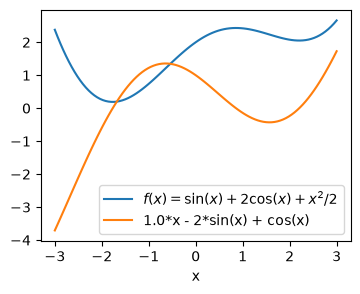

In [7]:
x = sp.symbols('x')
expr = sp.sin(x) + 2*  sp.cos(x) + 0.5 * x**2
df_expr = sp.diff(expr, x)

expr_np = sp.lambdify(x, expr, 'numpy')
dexpr_np = sp.lambdify(x, df_expr, 'numpy')

xnp = np.linspace(-3,3, 101)

fig,ax = plt.subplots( figsize=(4,3))
ax.plot(xnp, expr_np(xnp), label=r"$f(x) = \sin(x) + 2 \cos(x) + x^2/2$")
ax.plot(xnp, dexpr_np(xnp), label=f"{df_expr}")
ax.set_xlabel("x")
ax.legend()

plt.show()

In [10]:
def forward_derivation(f, x, h):
    return (f(x+h) - f(x)) /h

def backward_derivation(f, x, h):
    return (f(x) - f(x-h) ) /h

def central_derivation(f,x,h):
    return ( f(x+h) - f(x-h)) /(2. *h)

def fivepoint_derivation(f,x,h):
    return ( -f(x+2*h) + 8*f(x+h) - 8*f(x-h) + f(x-2*h) ) / (12.*h)

def func_np(x):
    return np.sin(x) + 2 * np.cos(x) + 0.5 * x**2

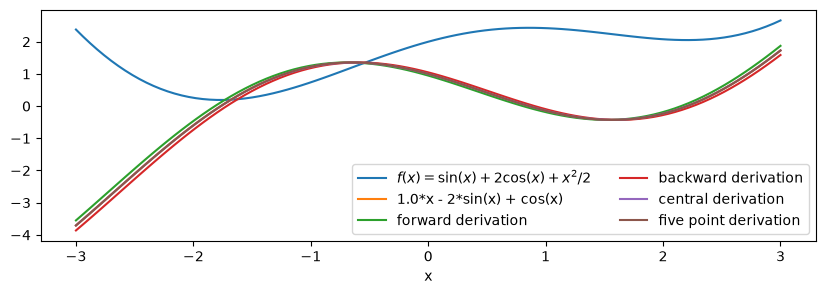

In [14]:
xnp = np.linspace(-3,3, 101)
h= 1e-1 

fig,ax = plt.subplots( figsize=(10,3))
ax.plot(xnp, expr_np(xnp), label=r"$f(x) = \sin(x) + 2 \cos(x) + x^2/2$")
ax.plot(xnp, dexpr_np(xnp), label=f"{df_expr}")

ax.plot(xnp, forward_derivation(func_np, xnp, h), label="forward derivation")
ax.plot(xnp, backward_derivation(func_np, xnp, h), label="backward derivation")
ax.plot(xnp, central_derivation(func_np, xnp, h), label="central derivation")
ax.plot(xnp, fivepoint_derivation(func_np, xnp, h), label="five point derivation")

ax.set_xlabel("x")
ax.legend(ncol=2)

plt.show()